##Simple IPython notebook to explore muscle cell model & channels

# Load and access cell

In [ ]:
import neuroml.loaders as loaders
from neuroml import Cell

cell_doc = loaders.NeuroMLLoader.load("SingleCompMuscle.cell.nml")
cell = cell_doc.cells[0]
print('Loaded cell: %s'%cell.id)

# Get information on morphology

In [ ]:
segment = cell.morphology.segments[0]
p = segment.proximal
d = segment.distal

print('Cell has a single segment (id: %s, name: %s) consisting of a cylinder from (%s, %s, %s) to (%s, %s, %s)' % 
      (segment.id, segment.name, p.x, p.y, p.z, d.x, d.y, d.z))

# Get information on membrane/channel properties

In [ ]:
membrane_properties = cell.biophysical_properties.membrane_properties
reversal_potentials = {}
densities = {}

for chan_dens in membrane_properties.channel_densities:
    reversal_potentials[chan_dens.id] = chan_dens.erev
    densities[chan_dens.id] = chan_dens.cond_density
    
print("Reversal potentials: %s"%reversal_potentials)
print("Channel densities: %s"%densities)

# Load channel files

In [ ]:
k_slow = loaders.NeuroMLLoader.load("k_slow.channel.nml").ion_channel[0]
k_fast = loaders.NeuroMLLoader.load("k_fast.channel.nml").ion_channel[0]
ca_boyle = loaders.NeuroMLLoader.load("ca_boyle.channel.nml").ion_channel[0]
leak_channel=loaders.NeuroMLLoader.load("Leak.channel.nml")

for chan in [k_slow, k_fast, ca_boyle,leak_channel]:
    print('Loaded channel: %s'%chan.id)
    for g in chan.gate_hh_tau_infs:
        print("  Gate %s present, instances %i"%(g.id,g.instances))
        if g.time_course:
            print("    Time course: %s, tau: %s"%(g.time_course.type, g.time_course.tau))
        if g.steady_state:
            print("    Steady state: %s, rate: %s, scale: %s, midpoint: %s"%(g.steady_state.type, g.steady_state.rate, g.steady_state.scale, g.steady_state.midpoint))


# Generating IV curves for Ion channels

### Configurations to import and verify cell dimensions

In [ ]:
import urllib.request                                                                                               #Import libraries to write cell dimensions for NeuroML files
import tempfile
from lems.model.model import Model
from math import pi

link = "https://raw.githubusercontent.com/NeuroML/NeuroML2/master/NeuroML2CoreTypes/NeuroMLCoreDimensions.xml"      
nml2_dims_contents = urllib.request.urlopen(link).read()
nml2_dims_file = tempfile.NamedTemporaryFile(delete=False)
nml2_dims_file.write(nml2_dims_contents)
nml2_dims_file.close()

model = Model()
model.import_from_file(nml2_dims_file.name)                                                                         #Store newly imported cell dimensions file

def get_si_value(nml2_value):
    return model.get_numeric_value(nml2_value, None)                                                                #Get SI value in usable format

assert(d.diameter==p.diameter)                                                                                      #Confirm proximal and distal cell components are of equal diameters
area_um2 = pi * (d.diameter) * ((d.x-p.x)**2 + (d.y-p.y)**2 + (d.z-p.z)**2)**0.5
area_m2 = get_si_value("%sum2"%area_um2)
cm_nml_str = cell.biophysical_properties.membrane_properties.specific_capacitances[0].value
nml2_Cmem = get_si_value(cm_nml_str) * area_m2

### Slow K<sup>+</sup> Channel

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt
from math import exp

nml2_GKS = get_si_value(densities['k_slow_all']) * nml2_Cmem
nml2_VKS = get_si_value(reversal_potentials['k_slow_all'])
nml2_v_half_n = get_si_value(k_slow.gate_hh_tau_infs[0].steady_state.midpoint)
nml2_k_n = get_si_value(k_slow.gate_hh_tau_infs[0].steady_state.scale)
nml2_T_n = get_si_value(k_slow.gate_hh_tau_infs[0].time_course.tau)

x = np.arange(-0.060, 0.080, 0.001)
numpoints = len(x)
y = np.zeros(numpoints)

def x_inf(V,Vhalf,k):
    return 1/(1 + exp((Vhalf - V)/k))                                                                       

for i in range(0,numpoints):
    IKS = nml2_GKS * x_inf(x[i], nml2_v_half_n, nml2_k_n) * (x[i] - nml2_VKS)
    y[i] = IKS  / nml2_Cmem

plt.plot([round(i * 1e3, 2) for i in x], [round(j * 1e2, 2) for j in y], 'k', label='$I_{Ks}$')
plt.xlim(-40,80)
plt.ylim(-8,6)
plt.ylabel('I_Ks (A/F)')
plt.xlabel('V (mV)')
plt.title("Slow K+ Channel")
plt.grid('on')



![Screenshot 2026-11-12 at 00.21.20.png](<attachment:Screenshot 2026-11-12 at 00.21.20.png>)
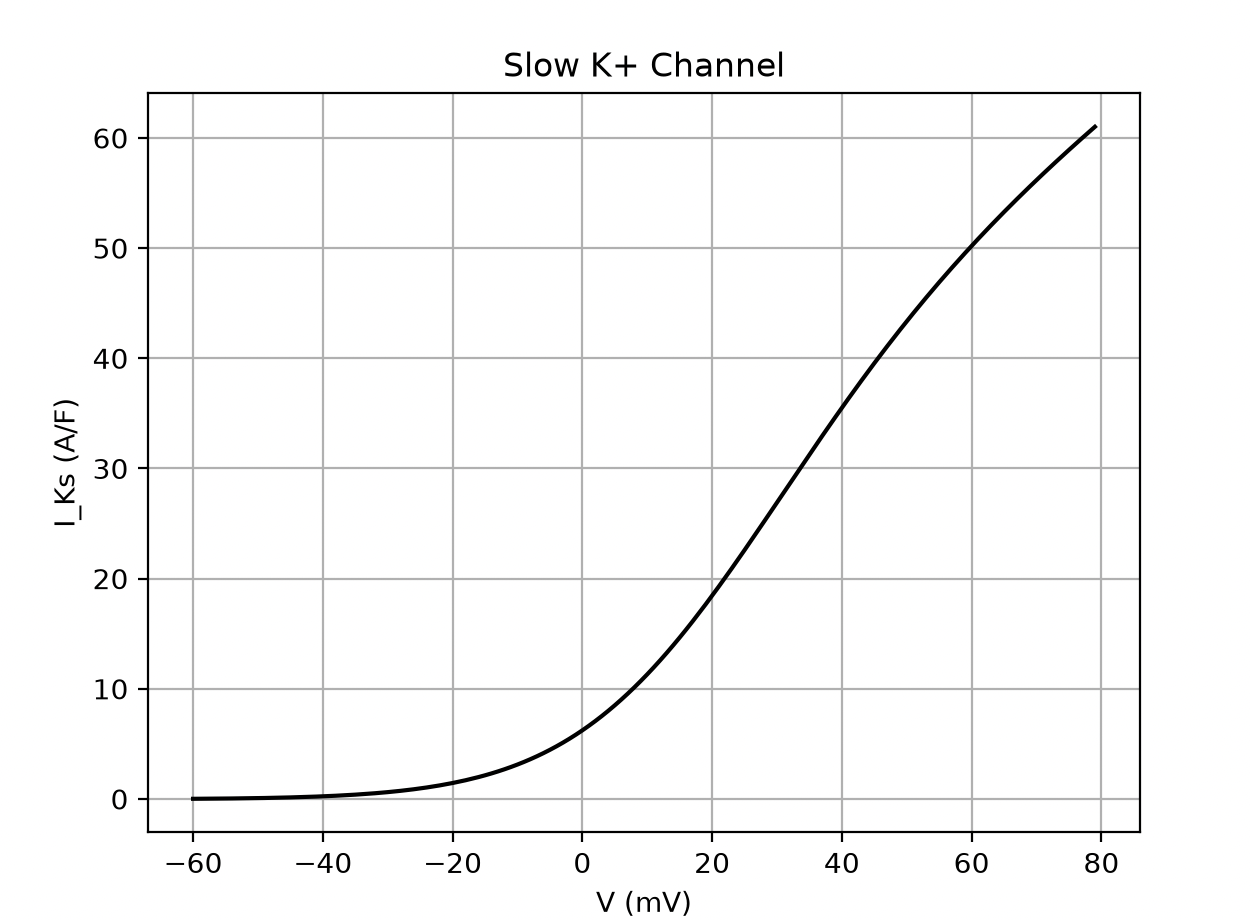

### Fast K<sup>+</sup> Channel 

In [ ]:
nml2_GKF = get_si_value(densities['k_fast_all']) * nml2_Cmem
nml2_VKF = get_si_value(reversal_potentials['k_fast_all'])
nml2_v_half_p = get_si_value(k_fast.gate_hh_tau_infs[0].steady_state.midpoint)
nml2_v_half_q = get_si_value(k_fast.gate_hh_tau_infs[1].steady_state.midpoint)
nml2_k_p = get_si_value(k_fast.gate_hh_tau_infs[0].steady_state.scale)
nml2_k_q = get_si_value(k_fast.gate_hh_tau_infs[1].steady_state.scale)
nml2_T_p = get_si_value(k_fast.gate_hh_tau_infs[0].time_course.tau)
nml2_T_q = get_si_value(k_fast.gate_hh_tau_infs[1].time_course.tau)

for i in range(0,numpoints):
    IKF = nml2_GKF * x_inf(x[i], nml2_v_half_p, nml2_k_p)**4 * x_inf(x[i], nml2_v_half_q, nml2_k_q) * (x[i]- nml2_VKF)
    y[i] = IKF  / nml2_Cmem

plt.plot([round(i * 1e3, 2) for i in x], [round(j * 1e2, 2) for j in y], 'k', label='$I_{Kf}$')
plt.xlim(-40,80)
plt.ylim(-8,6)
plt.ylabel('I_Kf (A/F)')
plt.xlabel('V (mV)')
plt.title("Fast K+ Channel")
plt.grid('on')


![Screenshot 2026-11-12 at 00.21.31.png](<attachment:Screenshot 2026-11-12 at 00.21.31.png>)
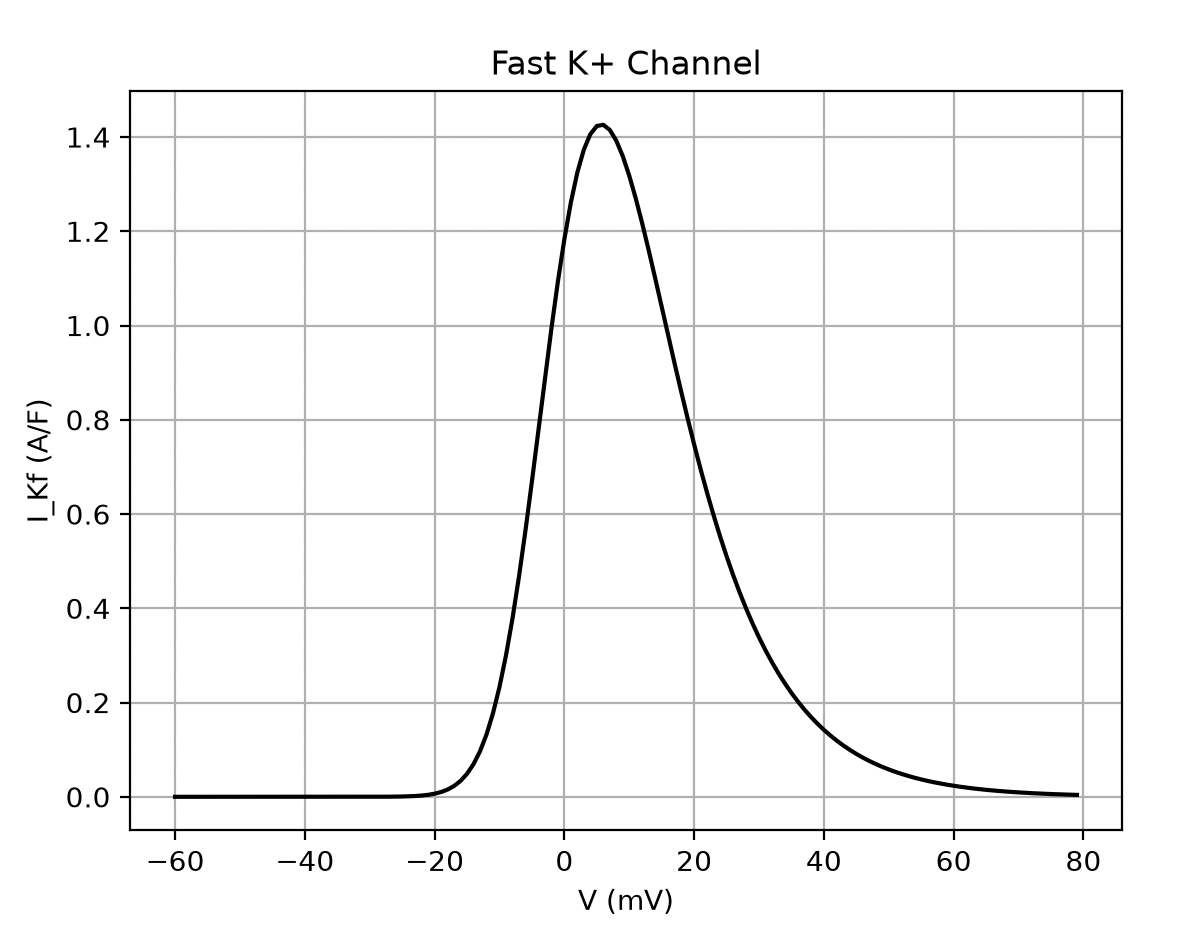

### Ca<sup>2+</sup> Boyle Channel

In [ ]:
import xml.etree.ElementTree as ET

tree = ET.parse('../../../NeuroML2/ca_boyle.channel.nml')

nml2_GCa = get_si_value(densities['ca_boyle_all']) * area_m2
nml2_VCa = get_si_value(reversal_potentials['ca_boyle_all'])
nml2_v_half_e = get_si_value(ca_boyle.gate_hh_tau_infs[0].steady_state.midpoint)
nml2_v_half_f = get_si_value(ca_boyle.gate_hh_tau_infs[1].steady_state.midpoint)
nml2_k_e = get_si_value(ca_boyle.gate_hh_tau_infs[0].steady_state.scale)
nml2_k_f = get_si_value(ca_boyle.gate_hh_tau_infs[1].steady_state.scale)
nml2_T_e = get_si_value(ca_boyle.gate_hh_tau_infs[0].time_course.tau)
nml2_T_f = get_si_value(ca_boyle.gate_hh_tau_infs[1].time_course.tau)

for c in tree.getroot().iter():
    if c.attrib.get('id') == 'h':
            nml2_cahalf_h = get_si_value(c.attrib['ca_half'])
            nml2_k_h = get_si_value(c.attrib['k'])
            nml2_alpha_ca = get_si_value(c.attrib['alpha'])

nml2_t_ca = get_si_value(ca_pool.decay_constant)
nml2_rho = get_si_value(ca_pool.rho)

for i in range(0,numpoints):
    ICa = nml2_GCa * x_inf(x[i], nml2_v_half_e, nml2_k_e)**2 * (x[i] - nml2_VCa)
    y[i] = ICa  / nml2_Cmem

plt.plot([round(i * 1e3, 2) for i in x], [round(j * 1e2, 2) for j in y], 'k', label='$I_{Ca}$')
plt.xlim(-40,80)
plt.ylim(-8,6)
plt.ylabel('I_Ca (A/F)')
plt.xlabel('V (mV)')
plt.title("Ca2+ Channel")
plt.grid('on')

![Screenshot 2026-11-12 at 00.19.28.png](<attachment:Screenshot 2026-11-12 at 00.19.28.png>)
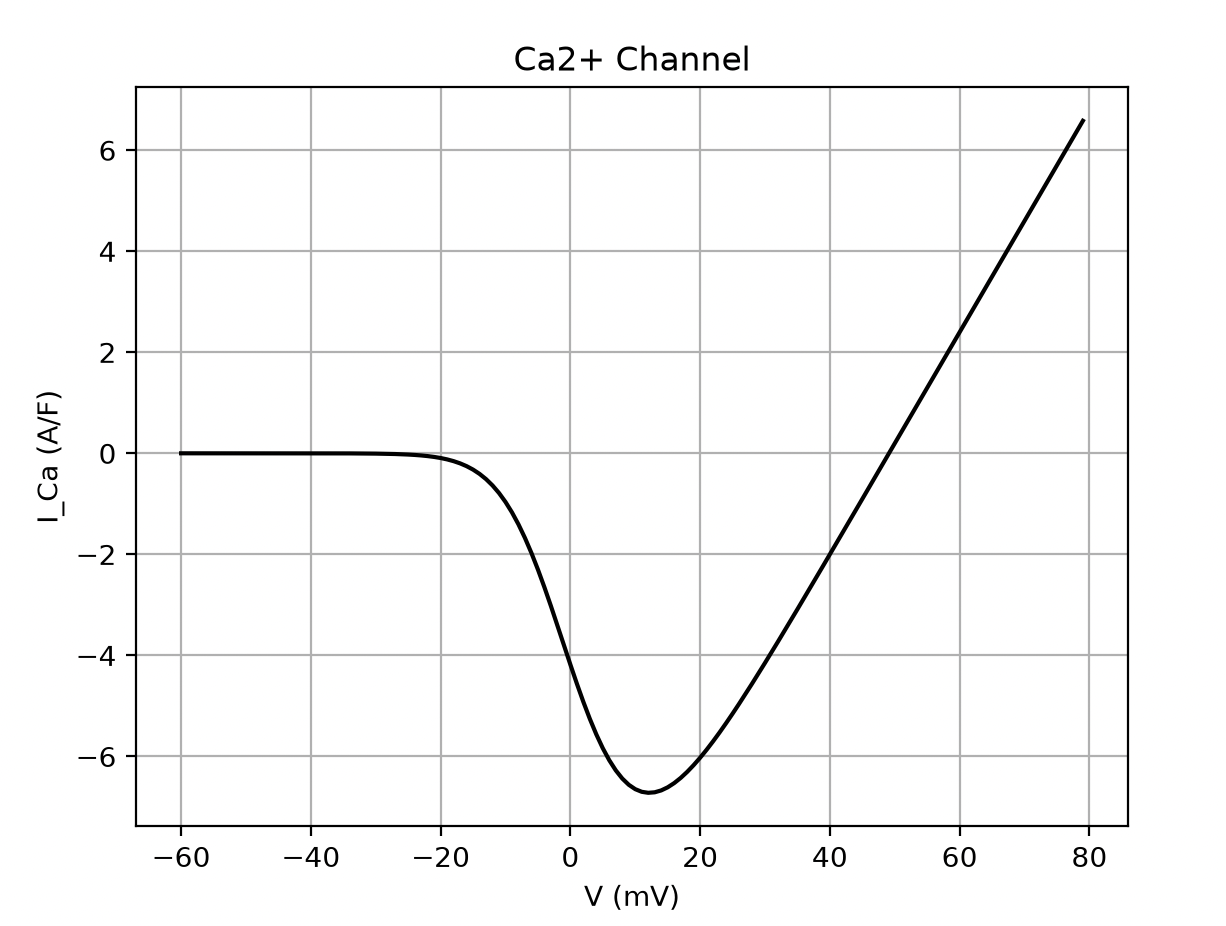

# Voltage Clamp Protocol

### Variable intialisation

In [ ]:
#Simulation Parameters 
deltat = 0.01e-3
duration = 0.03                 
numpoints = int(round(duration/deltat))
numtests = 11
xaxis = [round(x * 1e3, 2) for x in np.arange(deltat, duration+deltat, deltat)]

# Input parameters
onset = int(round(0.002/deltat))
offset = int(round(0.022/deltat))

# Variable Declaration
V = list()
I_mem = list()
Ca = list()
n = list()
p = list()
q = list()
e = list()
f = list()
h = list()

for i in range(0,numtests):
    V.append(list())
    I_mem.append(list())
    Ca.append(list())
    n.append(0)
    p.append(0)
    q.append(0)
    e.append(0)
    f.append(0)
    h.append(0)
   
    for j in range(0,numpoints):
        V[i].append(0)
        I_mem[i].append(0)
        Ca[i].append(0)

# Input initialization
for i in range(0,numtests):
    for j in range(0,numpoints):
        V[i][j] = -70e-3

Vstim = 40e-3
for i in range(0,numtests):
    for j in range(onset-1,offset):
        V[i][j] = Vstim
    Vstim = Vstim - 10e-3

# Variable initialization
for j in range(0,numtests):
    Ca[j][0] = 0
    n[j] = x_inf(V[j][0], nml2_v_half_n, nml2_k_n)
    p[j] = x_inf(V[j][0], nml2_v_half_p, nml2_k_p)
    q[j] = x_inf(V[j][0], nml2_v_half_q, nml2_k_q)
    e[j] = x_inf(V[j][0], nml2_v_half_e, nml2_k_e)
    f[j] = x_inf(V[j][0], nml2_v_half_f, nml2_k_f)


# Loading Leak Channel and its respective parameters
nml2_GL = get_si_value(densities['Leak_all']) * area_m2
nml2_VL = get_si_value(reversal_potentials['Leak_all'])

### Running Simulation

In [ ]:
# Start of simulation
for j in range(0,numtests):
    for i in range(1,numpoints):
        dn = (x_inf(V[j][i-1], nml2_v_half_n, nml2_k_n) - n[j])/nml2_T_n
        n[j] = n[j] + dn*deltat
        dp = (x_inf(V[j][i-1], nml2_v_half_p, nml2_k_p) - p[j])/nml2_T_p
        p[j] = p[j] + dp*deltat
        dq = (x_inf(V[j][i-1], nml2_v_half_q, nml2_k_q) - q[j])/nml2_T_q
        q[j] = q[j] + dq*deltat
        de = (x_inf(V[j][i-1], nml2_v_half_e, nml2_k_e) - e[j])/nml2_T_e
        e[j] = e[j] + de*deltat
        df = (x_inf(V[j][i-1], nml2_v_half_f, nml2_k_f) - f[j])/nml2_T_f
        f[j] = f[j] + df*deltat
        h[j] = x_inf(Ca[j][i-1], nml2_cahalf_h, nml2_k_h)
       
        IKS = nml2_GKS * n[j] * (V[j][i-1] - nml2_VKS)
        IKF = nml2_GKF * p[j]**4 * q[j] * (V[j][i-1] - nml2_VKF)
        ICa = nml2_GCa * e[j]**2 * f[j] * (1 + (h[j] - 1) * nml2_alpha_ca) * (V[j][i-1] - nml2_VCa)
        IL = nml2_GL * (V[j][i-1] - nml2_VL)

        dCa = -(Ca[j][i-1]/nml2_t_ca + nml2_rho*ICa)
        Ca[j][i] = Ca[j][i-1] + dCa*deltat

        I_mem[j][i] = (IKS + IKF + ICa + IL) 

### Plotting Results 

In [ ]:
for j in range(0, numtests):
    plt.plot(xaxis, [x * 1e9 for x in I_mem[j]])
plt.ylabel('Imem (nA)')
plt.xlabel('Time (ms)')
plt.show()

![Screenshot 2026-11-12 at 00.29.17.png](<attachment:Screenshot 2026-11-12 at 00.29.17.png>)
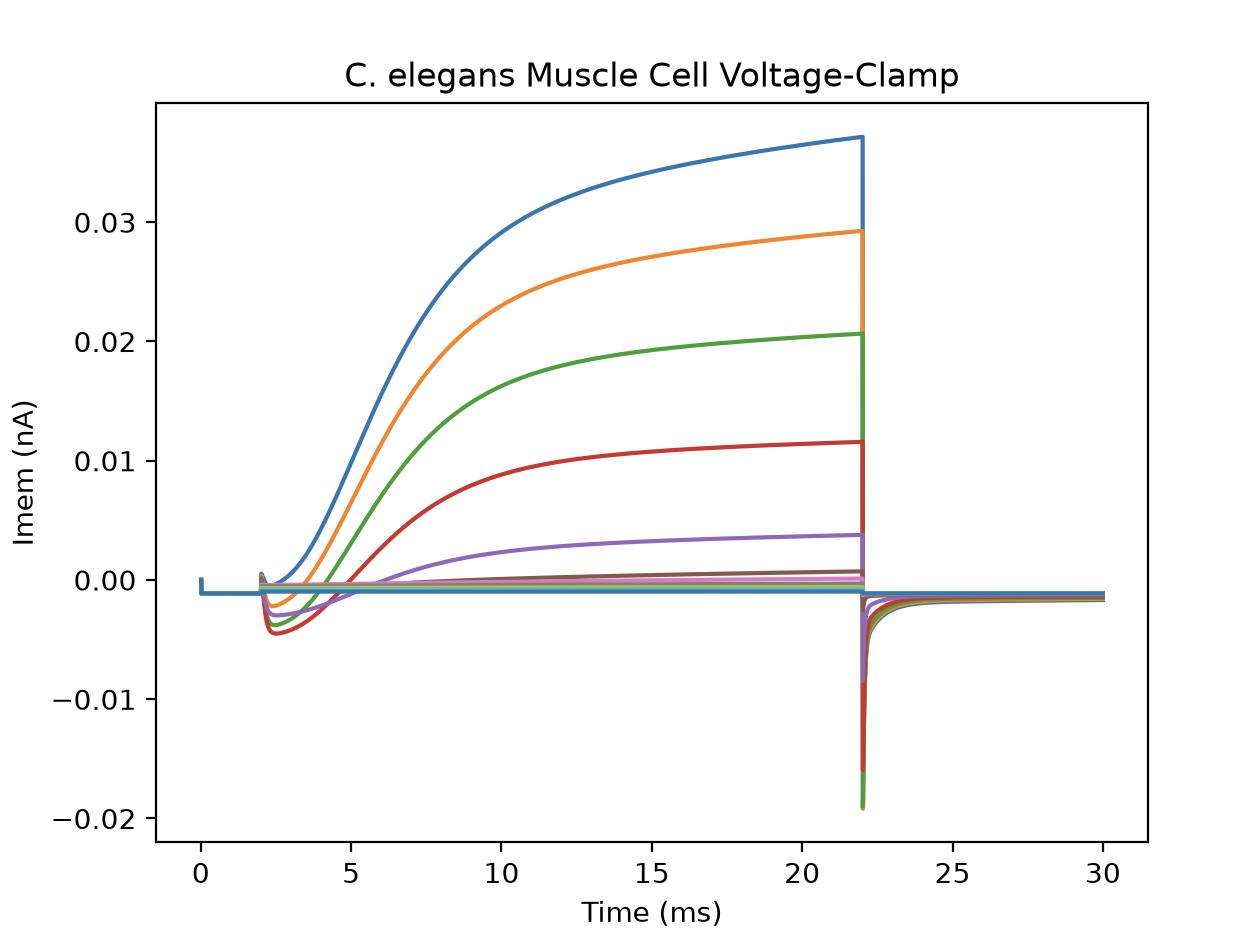

# Current Clamp Protocol

In [ ]:
deltat = 0.01e-3
duration = 1                 
numpoints = int(round(duration/deltat))
numtests = 7
xaxis = [round(x * 1e3, 2) for x in np.arange(deltat, duration+deltat, deltat)]

# Input parameters
onset = int(round(0.005/deltat))
offset = int(round(0.02/deltat))

# Variable Declaration
V = list()
Ca = list()
n = list()
p = list()
q = list()
e = list()
f = list()
h = list()
input_current = list()

for i in range(0,numtests):
    V.append(list())
    Ca.append(list())
    input_current.append(list())
    n.append(0)
    p.append(0)
    q.append(0)
    e.append(0)
    f.append(0)
    h.append(0)
   
    for j in range(0,numpoints):
        V[i].append(0)
        input_current[i].append(0)
        Ca[i].append(0)



# Input initialization
for i in range(0,numtests):
    for j in range(0,numpoints):
        input_current[i][j] = -120e-12

input_current_values = np.arange(100e-12, 800e-12, 100e-12)
for i in range(0,numtests):
    for j in range(onset,offset+1):
        input_current[i][j] = input_current_values[i] + input_current[i][j]
   


# Variable initialization
for j in range(0,numtests):
    V[j][0] = nml2_VL + input_current[0][0]/nml2_GL
    Ca[j][0] = 0
    n[j] = x_inf(V[j][0], nml2_v_half_n, nml2_k_n)
    p[j] = x_inf(V[j][0], nml2_v_half_p, nml2_k_p)
    q[j] = x_inf(V[j][0], nml2_v_half_q, nml2_k_q)
    e[j] = x_inf(V[j][0], nml2_v_half_e, nml2_k_e)
    f[j] = x_inf(V[j][0], nml2_v_half_f, nml2_k_f)


### Running Simulation

In [ ]:
# Start of simulation

for j in range(0,numtests):
    for i in range(1,numpoints):
        dn = (x_inf(V[j][i-1], nml2_v_half_n, nml2_k_n) - n[j])/nml2_T_n
        n[j] = n[j] + dn*deltat
        dp = (x_inf(V[j][i-1], nml2_v_half_p, nml2_k_p) - p[j])/nml2_T_p
        p[j] = p[j] + dp*deltat
        dq = (x_inf(V[j][i-1], nml2_v_half_q, nml2_k_q) - q[j])/nml2_T_q
        q[j] = q[j] + dq*deltat
        de = (x_inf(V[j][i-1], nml2_v_half_e, nml2_k_e) - e[j])/nml2_T_e
        e[j] = e[j] + de*deltat
        df = (x_inf(V[j][i-1], nml2_v_half_f, nml2_k_f) - f[j])/nml2_T_f
        f[j] = f[j] + df*deltat
        h[j] = x_inf(Ca[j][i-1], nml2_cahalf_h, nml2_k_h)
        # H_rec[i] = h[j]
        IKS = nml2_GKS * n[j] * (V[j][i-1] - nml2_VKS)
        IKF = nml2_GKF * p[j]**4 * q[j] * (V[j][i-1] - nml2_VKF)
        ICa = nml2_GCa * e[j]**2 * f[j] * (1 + (h[j] - 1) * nml2_alpha_ca) * (V[j][i-1] - nml2_VCa)
        IL = nml2_GL * (V[j][i-1] - nml2_VL)
        dCa = -(nml2_rho * ICa) - ((Ca[j][i - 1]) / nml2_t_ca)
        Ca[j][i] = Ca[j][i - 1] + dCa * deltat
        dV = (input_current[j][i-1] - IKS - IKF - ICa - IL)/nml2_Cmem
        V[j][i] = V[j][i-1] + dV*deltat

### Plotting Results 

In [ ]:
for j in range(0, numtests):
    plt.plot(xaxis, [x * 1e3 for x in V[j]])
plt.ylabel('Membrane Potential (mv)')
plt.xlabel('Time (ms)')
plt.show()

![Screenshot 2026-11-12 at 00.30.24.png](<attachment:Screenshot 2026-11-12 at 00.30.24.png>)
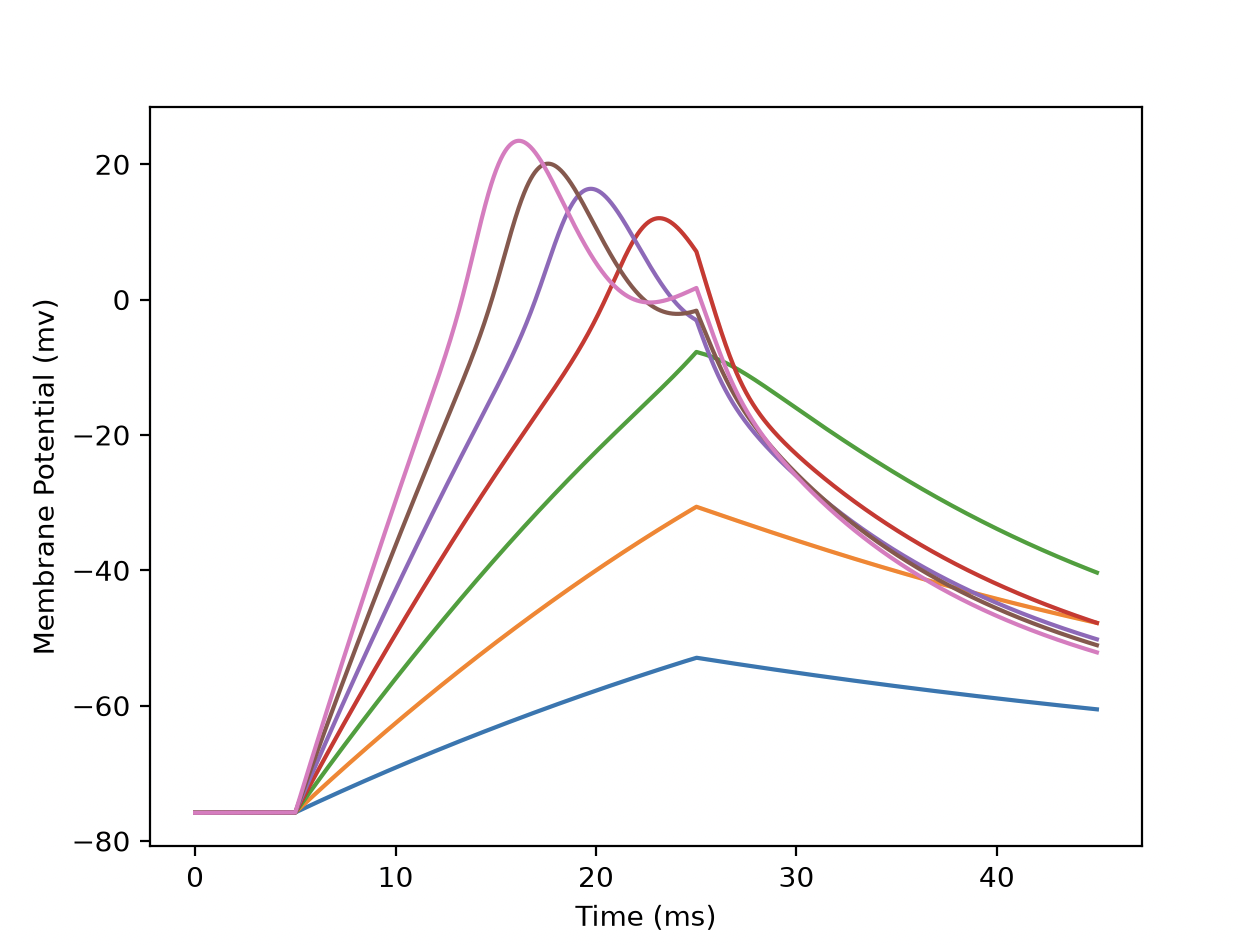